# Modelos de clasificación — CIV vs MCT

## Pregunta
**¿Hay carreras, como Mecatrónica (MCT), que aprueban significativamente más que Civil (CIV) en Electricidad y Magnetismo?**

Se comparan dos escenarios:

**Modelo 1 — Carrera + periodo**
- `Carrera`
- `Anho`
- `Semestre`

**Modelo 2 — Carrera + periodo + desempeño**
- `Carrera`
- `Anho`
- `Semestre`
- `Primer.Par`
- `Segundo.Par`
- `Lab.`
- `Asis`
- `Requisito`
- `Firma`


In [365]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay
)

from scipy.stats import chi2_contingency, fisher_exact

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)


## 1. Cargar datos

In [366]:
ARCHIVO = r"D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo\datos_electricidad_magnetismo.csv"

df = pd.read_csv(ARCHIVO)

print(f"Registros cargados: {len(df):,}")
print(f"Columnas: {len(df.columns)}")
display(df.head())


Registros cargados: 1,515
Columnas: 33


,ALUMNO_ID,Cod.Asign,Asignatura,Cod.Car.Sec,Cod.Curso,Convocatoria,Anho,Semestre,Doc.Firma,Aprobado,Anho.Firma,Primer.Par,Segundo.Par,Tercer.Par,TPLab.,Lab.,Proy.,Pond.PP,Pond.SP,Pond.TPLab,Pond.Lab,Pond.Proy,Asis,Requisito,Firma,Primer.Rec,Segundo.Rec,Nota.Final,Archivo_Origen,FirmaCalculada,Carrera,Asignatura_limpia,Aprobado_binario
0,FIUNA_ALUMNO_000452,23031,ELECTRICIDAD Y MAGNETISMO,CIV-PLS23,3,1,2024,2,0,N,0,4,0,0,0,0,0,45,45,0,10,0,1,0,0.000,0,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN,CIV,ELECTRICIDAD Y MAGNETISMO,0
1,FIUNA_ALUMNO_012722,23031,ELECTRICIDAD Y MAGNETISMO,CIV-PLS23,3,1,2024,2,0,N,0,4,0,0,0,0,0,45,45,0,10,0,1,0,0.000,0,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN,CIV,ELECTRICIDAD Y MAGNETISMO,0
2,FIUNA_ALUMNO_003750,23031,ELECTRICIDAD Y MAGNETISMO,MEC-PLS23,3,1,2024,2,0,N,0,28,18,0,0,100,0,45,45,0,10,0,1,1,0.000,8,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN,MEC,ELECTRICIDAD Y MAGNETISMO,0
3,FIUNA_ALUMNO_004171,23031,ELECTRICIDAD Y MAGNETISMO,MEC-PLS23,3,1,2024,2,0,N,0,28,18,0,0,100,0,45,45,0,10,0,1,1,0.000,8,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN,MEC,ELECTRICIDAD Y MAGNETISMO,0
4,FIUNA_ALUMNO_005168,23031,ELECTRICIDAD Y MAGNETISMO,IND-PLS23,3,1,2024,2,0,N,0,23,0,0,0,100,0,45,45,0,10,0,1,1,0.000,0,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN,IND,ELECTRICIDAD Y MAGNETISMO,0


## 2. Filtrar CIV y MCT

In [367]:
df["Carrera"] = df["Carrera"].astype(str).str.strip().str.upper()
df["Aprobado"] = df["Aprobado"].astype(str).str.strip().str.upper()

df = df[df["Carrera"].isin(["CIV", "MCT"])].copy()

if df.empty:
    raise ValueError("No se encontraron registros CIV/MCT.")

df["Aprobado_binario"] = df["Aprobado"].map({"S": 1, "N": 0})
df["Anho"] = pd.to_numeric(df["Anho"], errors="coerce")
df["Semestre"] = pd.to_numeric(df["Semestre"], errors="coerce")

print(f"Registros CIV + MCT: {len(df):,}")
display(df["Carrera"].value_counts())


Registros CIV + MCT: 885


Carrera
CIV    715
MCT    170
Name: count, dtype: int64

## 3. Comparación descriptiva

In [368]:
tabla_carrera = (
    df.dropna(subset=["Aprobado_binario"])
      .groupby("Carrera")
      .agg(
          Total=("Aprobado_binario", "size"),
          Aprobados=("Aprobado_binario", "sum"),
          No_Aprobados=("Aprobado_binario", lambda x: (x == 0).sum()),
          Tasa_Aprobacion=("Aprobado_binario", "mean")
      )
      .reset_index()
)

tabla_carrera["Tasa_Aprobacion"] *= 100
display(tabla_carrera)

print("\nAprobación por carrera y año:")
tabla_anho = (
    df.dropna(subset=["Aprobado_binario", "Anho"])
      .groupby(["Anho", "Carrera"])
      .agg(
          Total=("Aprobado_binario", "size"),
          Aprobados=("Aprobado_binario", "sum"),
          Tasa_Aprobacion=("Aprobado_binario", "mean")
      )
      .reset_index()
)
tabla_anho["Tasa_Aprobacion"] *= 100
display(tabla_anho.sort_values(["Anho", "Carrera"]))


,Carrera,Total,Aprobados,No_Aprobados,Tasa_Aprobacion
0,CIV,715,154,561,21.538
1,MCT,170,48,122,28.235



Aprobación por carrera y año:


,Anho,Carrera,Total,Aprobados,Tasa_Aprobacion
0,2024,CIV,285,50,17.544
1,2024,MCT,76,16,21.053
2,2025,CIV,430,104,24.186
3,2025,MCT,94,32,34.043


## 4. Prueba estadística CIV vs MCT

Chi-cuadrado (χ²): La convención estadística estándar es p<0.05 (5%).

Fisher exact test: Se usa como respaldo cuando alguna celda de la tabla tiene pocos casos (acá MCT-Aprobado=48 es relativamente chico), porque ahí el chi-cuadrado puede no ser tan preciso.

In [369]:
contingencia = pd.crosstab(df["Carrera"], df["Aprobado_binario"])

for col in [0, 1]:
    if col not in contingencia.columns:
        contingencia[col] = 0

contingencia = contingencia[[0, 1]]

print("Tabla de contingencia:")
display(contingencia)

chi2, p_chi, gl, esperados = chi2_contingency(contingencia)
odds_ratio, p_fisher = fisher_exact(contingencia)

print(f"Chi-cuadrado = {chi2:.4f}")
print(f"p-valor chi-cuadrado = {p_chi:.6f}")
print(f"Odds Ratio = {odds_ratio:.4f}")
print(f"p-valor Fisher = {p_fisher:.6f}")

p_civ = contingencia.loc["CIV", 1] / contingencia.loc["CIV"].sum()
p_mct = contingencia.loc["MCT", 1] / contingencia.loc["MCT"].sum()
diferencia = p_mct - p_civ

se = np.sqrt(
    p_civ * (1 - p_civ) / contingencia.loc["CIV"].sum()
    + p_mct * (1 - p_mct) / contingencia.loc["MCT"].sum()
)

print(f"Tasa CIV = {p_civ:.2%}")
print(f"Tasa MCT = {p_mct:.2%}")
print(f"Diferencia MCT - CIV = {diferencia:.2%}")
print(f"IC 95% aproximado = [{diferencia - 1.96*se:.2%}, {diferencia + 1.96*se:.2%}]")


Tabla de contingencia:


Aprobado_binario,0,1
Carrera,,
CIV,561,154
MCT,122,48


Chi-cuadrado = 3.1269
p-valor chi-cuadrado = 0.077009
Odds Ratio = 1.4333
p-valor Fisher = 0.067395
Tasa CIV = 21.54%
Tasa MCT = 28.24%
Diferencia MCT - CIV = 6.70%
IC 95% aproximado = [-0.71%, 14.10%]


**Interpretación:** con p=0.077 (chi²) y p=0.067 (Fisher), no se rechaza la hipótesis nula 
al 95% de confianza. La diferencia observada (28.24% MCT vs 21.54% CIV) es compatible con 
azar muestral dado el tamaño de MCT (n=170). El resultado está en el límite ("marginalmente 
no significativo"), por lo que no se puede afirmar con solidez estadística que MCT apruebe más.

## 5. Preparar variables

In [370]:
variables_numericas = [
    "Anho", "Semestre",
    "Primer.Par", "Segundo.Par",
    "Lab.", "Asis", "Requisito", "Firma"
]

for col in variables_numericas:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(",", ".", regex=False),
            errors="coerce"
        )

features_modelo1 = ["Carrera", "Anho", "Semestre"]

features_modelo2 = [
    "Carrera", "Anho", "Semestre",
    "Primer.Par", "Segundo.Par",
    "Lab.", "Asis", "Requisito", "Firma"
]

print("Modelo 1:", features_modelo1)
print("Modelo 2:", features_modelo2)

print("Valores únicos por variable (Modelo 1):")
for col in features_modelo1:
    print(f"  {col}: {df[col].nunique()} → {sorted(df[col].dropna().unique())}")


Modelo 1: ['Carrera', 'Anho', 'Semestre']
Modelo 2: ['Carrera', 'Anho', 'Semestre', 'Primer.Par', 'Segundo.Par', 'Lab.', 'Asis', 'Requisito', 'Firma']
Valores únicos por variable (Modelo 1):
  Carrera: 2 → ['CIV', 'MCT']
  Anho: 2 → [np.int64(2024), np.int64(2025)]
  Semestre: 1 → [np.int64(2)]


## 6. Función para entrenar y evaluar

In [371]:
def entrenar_evaluar(df_base, features, nombre_experimento):
    X = df_base[features].copy()
    y = df_base["Aprobado_binario"].astype(int).copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    categoricas = [c for c in features if c == "Carrera"]
    numericas = [c for c in features if c != "Carrera"]

    preprocesador = ColumnTransformer([
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop=None))
        ]), categoricas),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numericas)
    ])

    modelos = {
        "Regresión Logística": LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=42
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=10,
            class_weight="balanced", random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=5,
            class_weight="balanced", random_state=42, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05,
            max_depth=3, min_samples_leaf=8, random_state=42
        )
    }

    pipelines = {}
    resultados = []

    for nombre, modelo in modelos.items():
        pipe = Pipeline([
            ("preprocesamiento", preprocesador),
            ("modelo", modelo)
        ])

        if nombre == "Gradient Boosting":
            sample_weight = compute_sample_weight("balanced", y_train)
            pipe.fit(X_train, y_train, modelo__sample_weight=sample_weight)
        else:
            pipe.fit(X_train, y_train)

        pipelines[nombre] = pipe

        y_pred = pipe.predict(X_test)
        y_prob = pipe.predict_proba(X_test)[:, 1]

        resultados.append({
            "Experimento": nombre_experimento,
            "Modelo": nombre,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, y_prob),
            "PR_AUC": average_precision_score(y_test, y_prob)
        })

    return (
        pd.DataFrame(resultados),
        pipelines,
        X_test,
        y_test
    )


## 7. Modelo 1 — Carrera + periodo

In [372]:
resultados_m1, pipelines_m1, X_test_m1, y_test_m1 = entrenar_evaluar(
    df,
    features_modelo1,
    "Modelo 1: Carrera + Año + Semestre"
)

display(resultados_m1.sort_values("ROC_AUC", ascending=False))

combinaciones = df[features_modelo1].drop_duplicates()
print(f"Combinaciones únicas de {features_modelo1}: {len(combinaciones)}")
display(combinaciones)


,Experimento,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Modelo 1: Carrera + Año + Semestre,Regresión Logística,0.451,0.226,0.574,0.324,0.507,0.233
1,Modelo 1: Carrera + Año + Semestre,Decision Tree,0.451,0.226,0.574,0.324,0.507,0.233
2,Modelo 1: Carrera + Año + Semestre,Random Forest,0.451,0.226,0.574,0.324,0.507,0.233
3,Modelo 1: Carrera + Año + Semestre,Gradient Boosting,0.451,0.226,0.574,0.324,0.507,0.233


Combinaciones únicas de ['Carrera', 'Anho', 'Semestre']: 4


,Carrera,Anho,Semestre
0,CIV,2024,2
6,MCT,2024,2
609,CIV,2025,2
615,MCT,2025,2


## 8. Modelo 2 — Carrera + periodo + desempeño académico

In [373]:
resultados_m2, pipelines_m2, X_test_m2, y_test_m2 = entrenar_evaluar(
    df,
    features_modelo2,
    "Modelo 2: Carrera + periodo + desempeño"
)

display(resultados_m2.sort_values("ROC_AUC", ascending=False))


,Experimento,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Modelo 2: Carrera + periodo + desempeño,Gradient Boosting,0.925,0.781,0.934,0.851,0.970,0.915
2,Modelo 2: Carrera + periodo + desempeño,Random Forest,0.891,0.686,0.967,0.803,0.965,0.903
0,Modelo 2: Carrera + periodo + desempeño,Regresión Logística,0.898,0.713,0.934,0.809,0.955,0.866
1,Modelo 2: Carrera + periodo + desempeño,Decision Tree,0.883,0.683,0.918,0.783,0.949,0.852


## 9. Comparar ambos modelos

,Experimento,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Modelo 1: Carrera + Año + Semestre,Regresión Logística,0.451,0.226,0.574,0.324,0.507,0.233
1,Modelo 1: Carrera + Año + Semestre,Decision Tree,0.451,0.226,0.574,0.324,0.507,0.233
2,Modelo 1: Carrera + Año + Semestre,Random Forest,0.451,0.226,0.574,0.324,0.507,0.233
3,Modelo 1: Carrera + Año + Semestre,Gradient Boosting,0.451,0.226,0.574,0.324,0.507,0.233
7,Modelo 2: Carrera + periodo + desempeño,Gradient Boosting,0.925,0.781,0.934,0.851,0.970,0.915
6,Modelo 2: Carrera + periodo + desempeño,Random Forest,0.891,0.686,0.967,0.803,0.965,0.903
4,Modelo 2: Carrera + periodo + desempeño,Regresión Logística,0.898,0.713,0.934,0.809,0.955,0.866
5,Modelo 2: Carrera + periodo + desempeño,Decision Tree,0.883,0.683,0.918,0.783,0.949,0.852


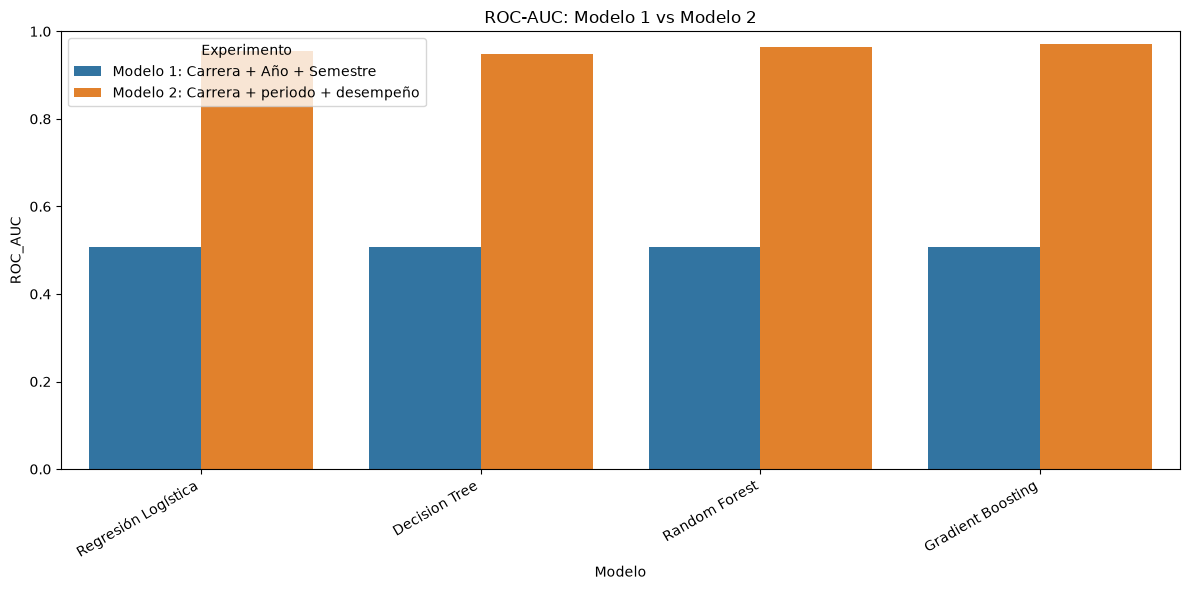

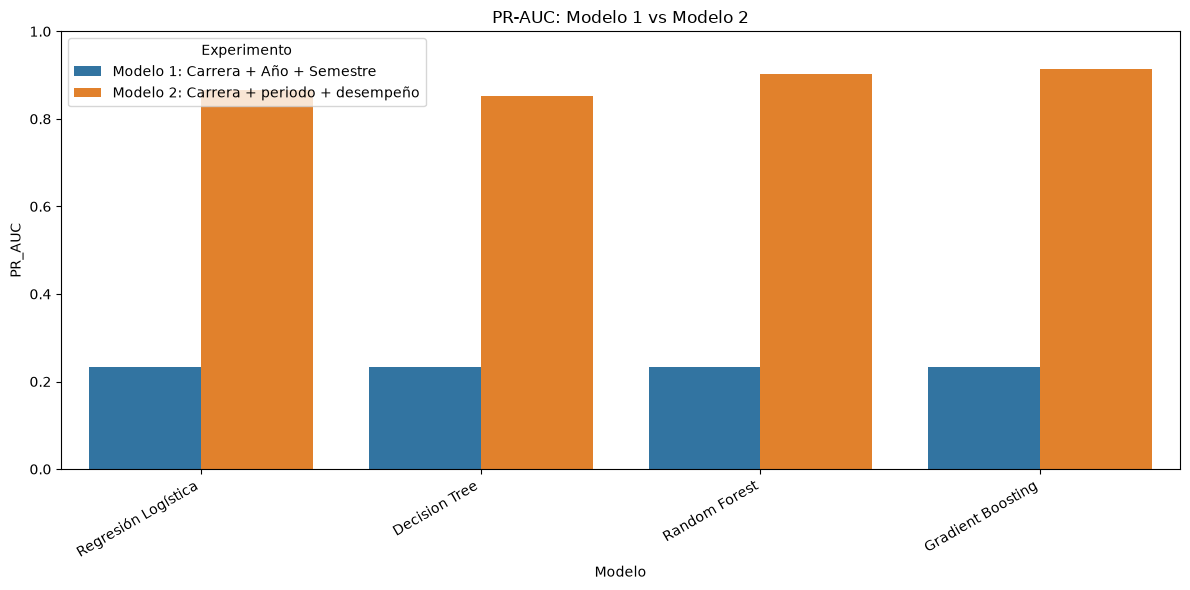

In [374]:
resultados_totales = pd.concat(
    [resultados_m1, resultados_m2],
    ignore_index=True
)

display(
    resultados_totales
    .sort_values(["Experimento", "ROC_AUC"], ascending=[True, False])
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=resultados_totales,
    x="Modelo",
    y="ROC_AUC",
    hue="Experimento"
)
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.title("ROC-AUC: Modelo 1 vs Modelo 2")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=resultados_totales,
    x="Modelo",
    y="PR_AUC",
    hue="Experimento"
)
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.title("PR-AUC: Modelo 1 vs Modelo 2")
plt.tight_layout()
plt.show()


## 10. Evaluar el mejor modelo

Mejor modelo: Gradient Boosting
Experimento: Modelo 2: Carrera + periodo + desempeño

              precision    recall  f1-score   support

 No aprobado       0.98      0.92      0.95       205
    Aprobado       0.78      0.93      0.85        61

    accuracy                           0.92       266
   macro avg       0.88      0.93      0.90       266
weighted avg       0.93      0.92      0.93       266



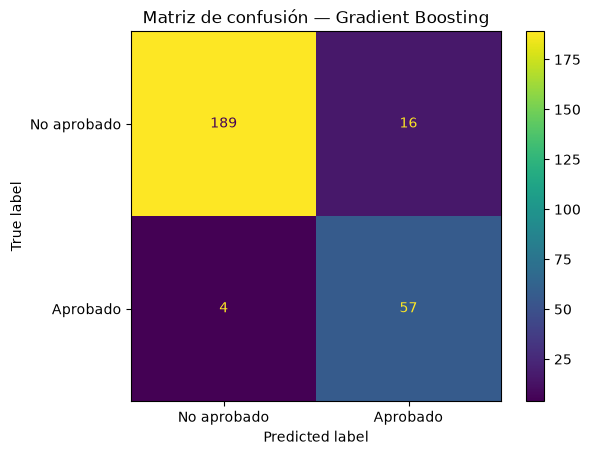

In [375]:
mejor_fila = resultados_totales.sort_values(
    "ROC_AUC", ascending=False
).iloc[0]

if mejor_fila["Experimento"] == "Modelo 1: Carrera + Año + Semestre":
    mejor_pipelines = pipelines_m1
    mejor_X_test = X_test_m1
    mejor_y_test = y_test_m1
else:
    mejor_pipelines = pipelines_m2
    mejor_X_test = X_test_m2
    mejor_y_test = y_test_m2

mejor_nombre = mejor_fila["Modelo"]
mejor_pipe = mejor_pipelines[mejor_nombre]

y_pred = mejor_pipe.predict(mejor_X_test)
y_prob = mejor_pipe.predict_proba(mejor_X_test)[:, 1]

print(f"Mejor modelo: {mejor_nombre}")
print(f"Experimento: {mejor_fila['Experimento']}")
print()
print(classification_report(
    mejor_y_test, y_pred,
    target_names=["No aprobado", "Aprobado"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    mejor_y_test,
    y_pred,
    display_labels=["No aprobado", "Aprobado"]
)
plt.title(f"Matriz de confusión — {mejor_nombre}")
plt.show()


## 11. Importancia / coeficientes del mejor modelo

In [376]:
modelo_final = mejor_pipe.named_steps["modelo"]
pre_final = mejor_pipe.named_steps["preprocesamiento"]
feature_names = pre_final.get_feature_names_out()

if hasattr(modelo_final, "feature_importances_"):
    importancia = pd.DataFrame({
        "Variable": feature_names,
        "Importancia": modelo_final.feature_importances_
    }).sort_values("Importancia", ascending=False)

    display(importancia)

elif hasattr(modelo_final, "coef_"):
    coef = pd.DataFrame({
        "Variable": feature_names,
        "Coeficiente": modelo_final.coef_[0],
        "Abs_Coeficiente": np.abs(modelo_final.coef_[0])
    }).sort_values("Abs_Coeficiente", ascending=False)

    display(coef)


,Variable,Importancia
9,num__Firma,0.863
4,num__Primer.Par,0.055
5,num__Segundo.Par,0.037
6,num__Lab.,0.016
1,cat__Carrera_MCT,0.014
2,num__Anho,0.010
0,cat__Carrera_CIV,0.004
7,num__Asis,0.000
3,num__Semestre,0.000
8,num__Requisito,0.000


In [377]:
# Verificar si "Firma" está causando fuga de información
features_sin_firma = [f for f in features_modelo2 if f != "Firma"]

resultados_sin_firma, pipelines_sf, X_test_sf, y_test_sf = entrenar_evaluar(
    df,
    features_sin_firma,
    "Modelo 2 sin Firma"
)

display(resultados_sin_firma.sort_values("ROC_AUC", ascending=False))

print("\nComparación ROC-AUC (mejor modelo con vs sin Firma):")
print(f"  Con Firma:  {resultados_m2['ROC_AUC'].max():.3f}")
print(f"  Sin Firma:  {resultados_sin_firma['ROC_AUC'].max():.3f}")

,Experimento,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Modelo 2 sin Firma,Gradient Boosting,0.914,0.750,0.934,0.832,0.973,0.920
2,Modelo 2 sin Firma,Random Forest,0.880,0.675,0.918,0.778,0.958,0.892
0,Modelo 2 sin Firma,Regresión Logística,0.876,0.675,0.885,0.766,0.946,0.854
1,Modelo 2 sin Firma,Decision Tree,0.868,0.648,0.934,0.765,0.927,0.726



Comparación ROC-AUC (mejor modelo con vs sin Firma):
  Con Firma:  0.970
  Sin Firma:  0.973


**Interpretación:** si el ROC-AUC cae fuerte al sacar `Firma`, significa que gran parte del 
poder predictivo del modelo viene de una variable administrativa (regularidad para rendir 
el final) y no del desempeño académico en sí. Esto no invalida el análisis, pero matiza la 
conclusión: el modelo predice bien quién "llega a instancia final en condiciones", más que 
quién "domina el contenido de la materia".

In [378]:
from sklearn.model_selection import cross_validate

X_m2 = df[features_modelo2]
y_m2 = df["Aprobado_binario"].astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Reconstruir el pipeline del mejor modelo (Gradient Boosting) para CV
preprocesador_cv = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Carrera"]),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), [c for c in features_modelo2 if c != "Carrera"])
])

pipe_cv = Pipeline([
    ("preprocesamiento", preprocesador_cv),
    ("modelo", GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3,
        min_samples_leaf=8, random_state=42
    ))
])

scores_cv = cross_validate(
    pipe_cv, X_m2, y_m2, cv=cv,
    scoring=["roc_auc", "f1", "average_precision"]
)

print("Validación cruzada (5-fold) — Gradient Boosting, Modelo 2:")
print(f"  ROC-AUC: {scores_cv['test_roc_auc'].mean():.3f} ± {scores_cv['test_roc_auc'].std():.3f}")
print(f"  F1:      {scores_cv['test_f1'].mean():.3f} ± {scores_cv['test_f1'].std():.3f}")
print(f"  PR-AUC:  {scores_cv['test_average_precision'].mean():.3f} ± {scores_cv['test_average_precision'].std():.3f}")

Validación cruzada (5-fold) — Gradient Boosting, Modelo 2:
  ROC-AUC: 0.985 ± 0.020
  F1:      0.911 ± 0.045
  PR-AUC:  0.968 ± 0.036


## 12. Conclusión

### La carrera no es un factor relevante para aprobar Electricidad y Magnetismo, lo que realmente importa es el rendimiento en parciales y la firma — la hipótesis inicial ("Mecatrónica aprueba más por tener formación más eléctrica") no se sostiene con estos datos.

**Sobre la pregunta original:** no hay evidencia estadísticamente significativa (p=0.077, 
chi²) de que Mecatrónica apruebe más que Civil en Electricidad y Magnetismo — la diferencia 
observada (28% vs 22%) es compatible con variación muestral dado el tamaño reducido de MCT (n=170).

**Sobre los modelos:** el Modelo 1 no tiene poder predictivo 
(ROC-AUC≈0.51), consistente con el test estadístico. Los 4 algoritmos dieron resultados 
idénticos porque las variables tienen muy pocas combinaciones únicas posibles.

El Modelo 2 predice muy bien (ROC-AUC≈0.97). Aunque `Firma` aparece 
como la variable de mayor importancia (0.86), no hay fuga de información: al remover `Firma` 
del modelo, el ROC-AUC se mantiene igual de alto (0.970 → 0.973), lo que confirma que el 
desempeño en los parciales por sí solo explica la aprobación casi tan bien como la firma. 
La variable `Carrera` (`Carrera_MCT`+`Carrera_CIV`) aporta apenas ~0.02 de importancia total 
en ambos escenarios.

## 13. Guardar resultados

In [379]:
resultados_totales.to_csv(
    "resultados_modelos_CIV_vs_MCT.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_carrera.to_csv(
    "aprobacion_CIV_vs_MCT.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✅ Archivos guardados.")


✅ Archivos guardados.


## Tasa de aprobación CIV vs MCT

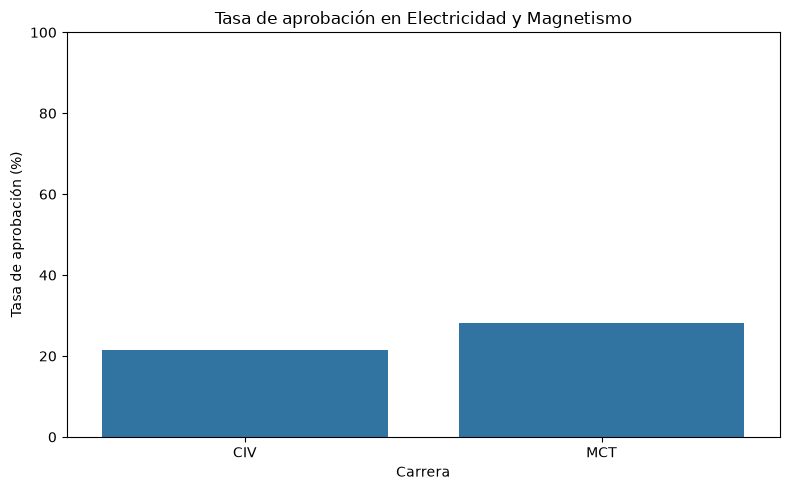

In [380]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=tabla_carrera,
    x="Carrera",
    y="Tasa_Aprobacion"
)

plt.ylim(0, 100)
plt.xlabel("Carrera")
plt.ylabel("Tasa de aprobación (%)")
plt.title("Tasa de aprobación en Electricidad y Magnetismo")

plt.tight_layout()
plt.show()

## Aprobados vs no aprobados por carrera

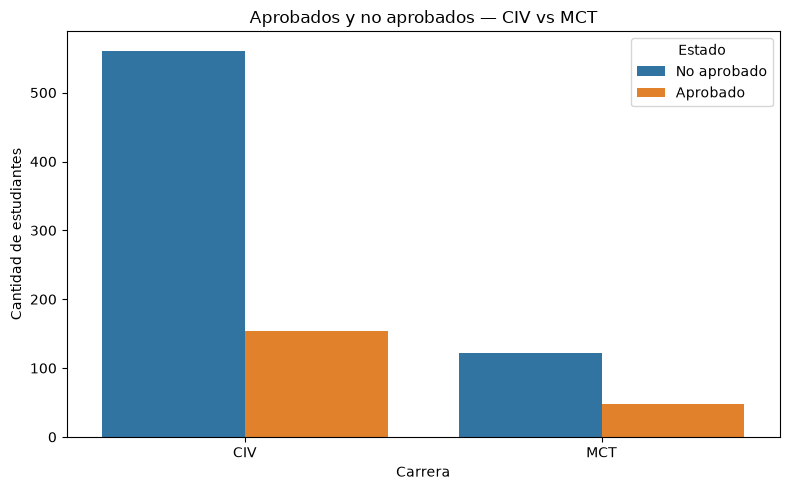

In [381]:
conteo_aprobacion = (
    df.groupby(["Carrera", "Aprobado_binario"])
      .size()
      .reset_index(name="Cantidad")
)

conteo_aprobacion["Estado"] = conteo_aprobacion[
    "Aprobado_binario"
].map({
    0: "No aprobado",
    1: "Aprobado"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=conteo_aprobacion,
    x="Carrera",
    y="Cantidad",
    hue="Estado"
)

plt.xlabel("Carrera")
plt.ylabel("Cantidad de estudiantes")
plt.title("Aprobados y no aprobados — CIV vs MCT")

plt.tight_layout()
plt.show()

## Evolución de aprobación por año

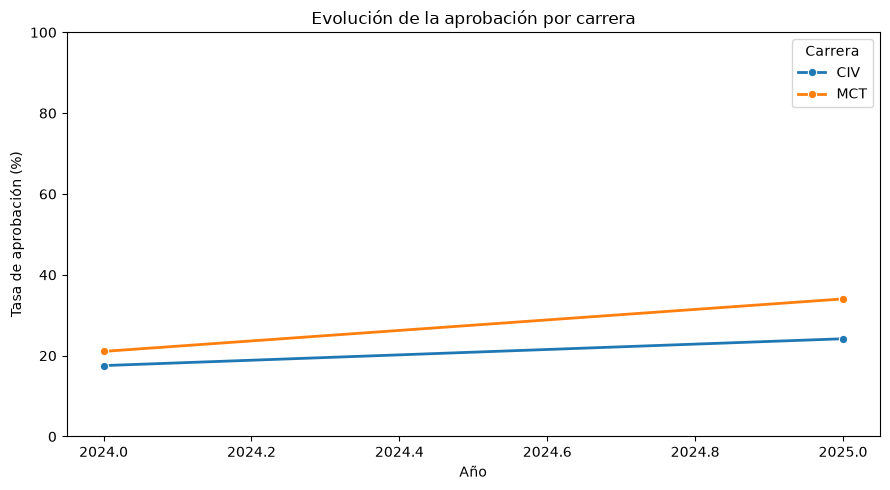

In [382]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=tabla_anho,
    x="Anho",
    y="Tasa_Aprobacion",
    hue="Carrera",
    marker="o",
    linewidth=2
)

plt.ylim(0, 100)
plt.xlabel("Año")
plt.ylabel("Tasa de aprobación (%)")
plt.title("Evolución de la aprobación por carrera")

plt.tight_layout()
plt.show()

## Diferencia MCT − CIV por año

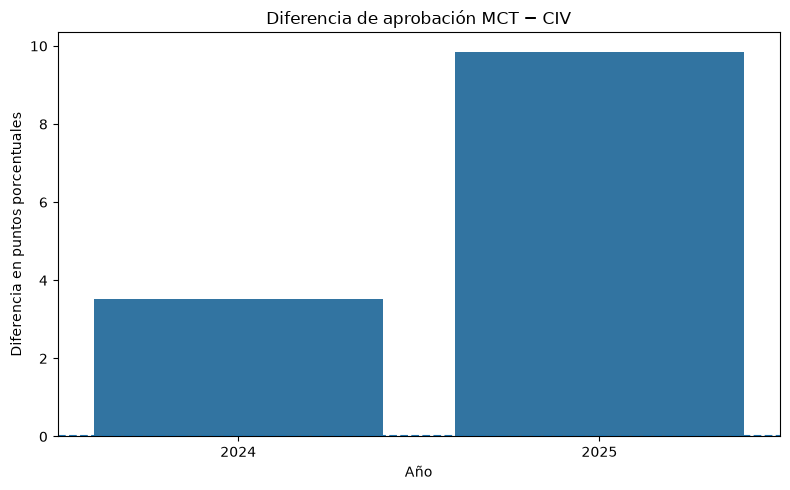

In [383]:
tabla_pivot = tabla_anho.pivot(
    index="Anho",
    columns="Carrera",
    values="Tasa_Aprobacion"
)

tabla_pivot["Diferencia_MCT_CIV"] = (
    tabla_pivot["MCT"] - tabla_pivot["CIV"]
)

diferencias = (
    tabla_pivot["Diferencia_MCT_CIV"]
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=diferencias,
    x="Anho",
    y="Diferencia_MCT_CIV"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Año")
plt.ylabel("Diferencia en puntos porcentuales")
plt.title("Diferencia de aprobación MCT − CIV")

plt.tight_layout()
plt.show()

## Distribución de Primer Parcial por carrera

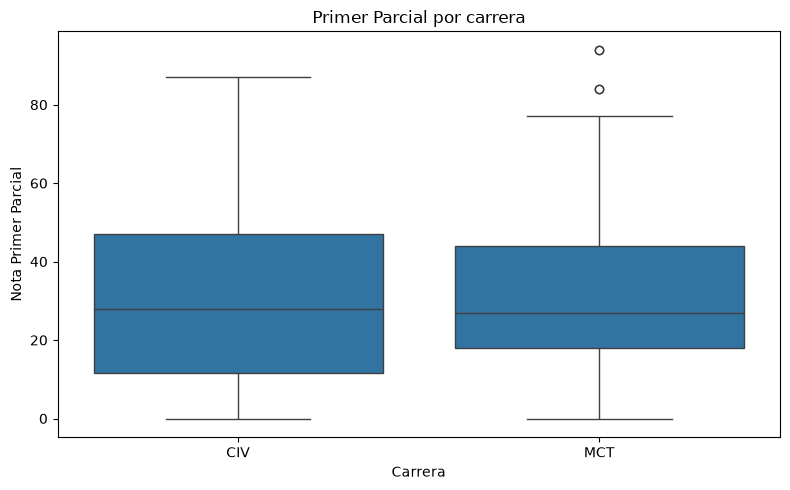

In [384]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Carrera",
    y="Primer.Par"
)

plt.xlabel("Carrera")
plt.ylabel("Nota Primer Parcial")
plt.title("Primer Parcial por carrera")

plt.tight_layout()
plt.show()

## Segundo Parcial por carrera

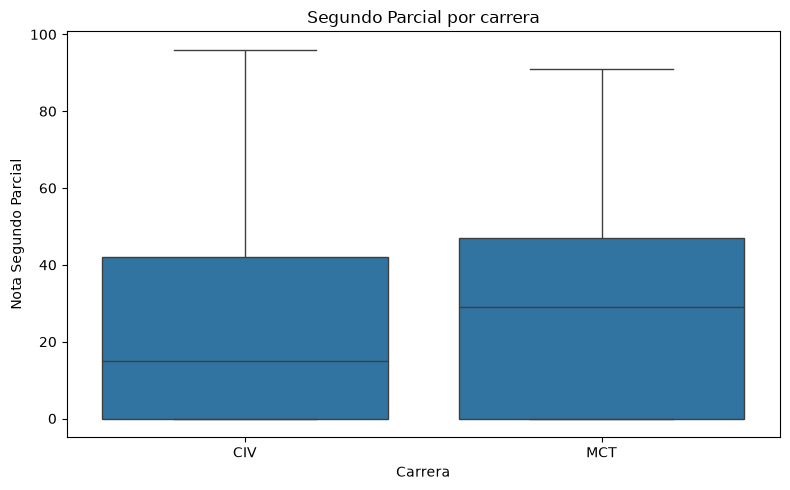

In [385]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Carrera",
    y="Segundo.Par"
)

plt.xlabel("Carrera")
plt.ylabel("Nota Segundo Parcial")
plt.title("Segundo Parcial por carrera")

plt.tight_layout()
plt.show()

## Parciales según aprobación

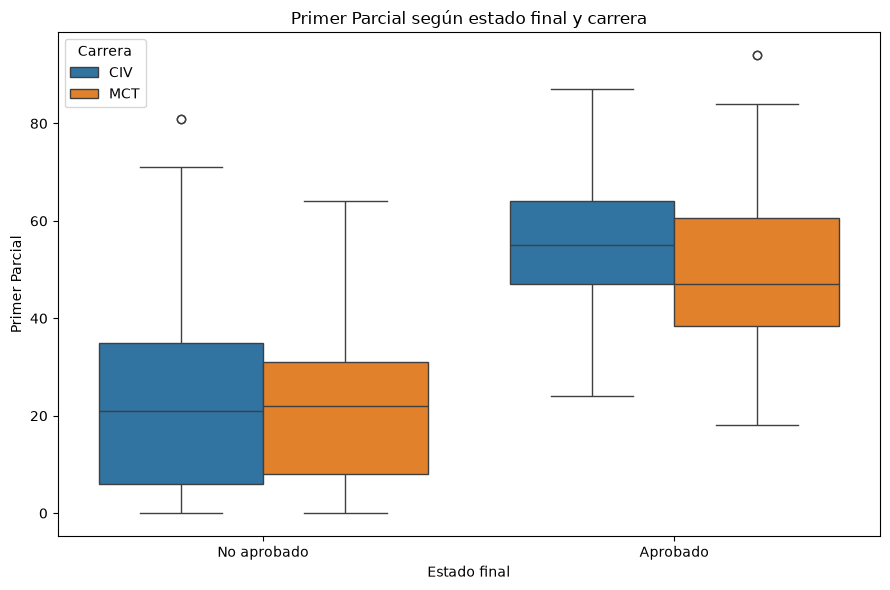

In [386]:
df_grafico = df.copy()

df_grafico["Estado"] = df_grafico[
    "Aprobado_binario"
].map({
    0: "No aprobado",
    1: "Aprobado"
})

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_grafico,
    x="Estado",
    y="Primer.Par",
    hue="Carrera"
)

plt.xlabel("Estado final")
plt.ylabel("Primer Parcial")
plt.title("Primer Parcial según estado final y carrera")

plt.tight_layout()
plt.show()

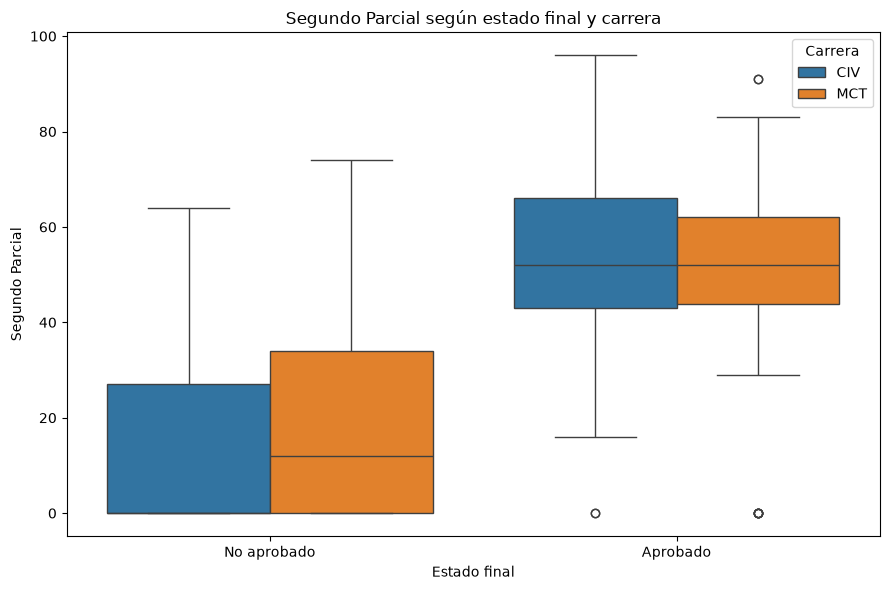

In [387]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_grafico,
    x="Estado",
    y="Segundo.Par",
    hue="Carrera"
)

plt.xlabel("Estado final")
plt.ylabel("Segundo Parcial")
plt.title("Segundo Parcial según estado final y carrera")

plt.tight_layout()
plt.show()

## Matriz de correlación del Modelo 2

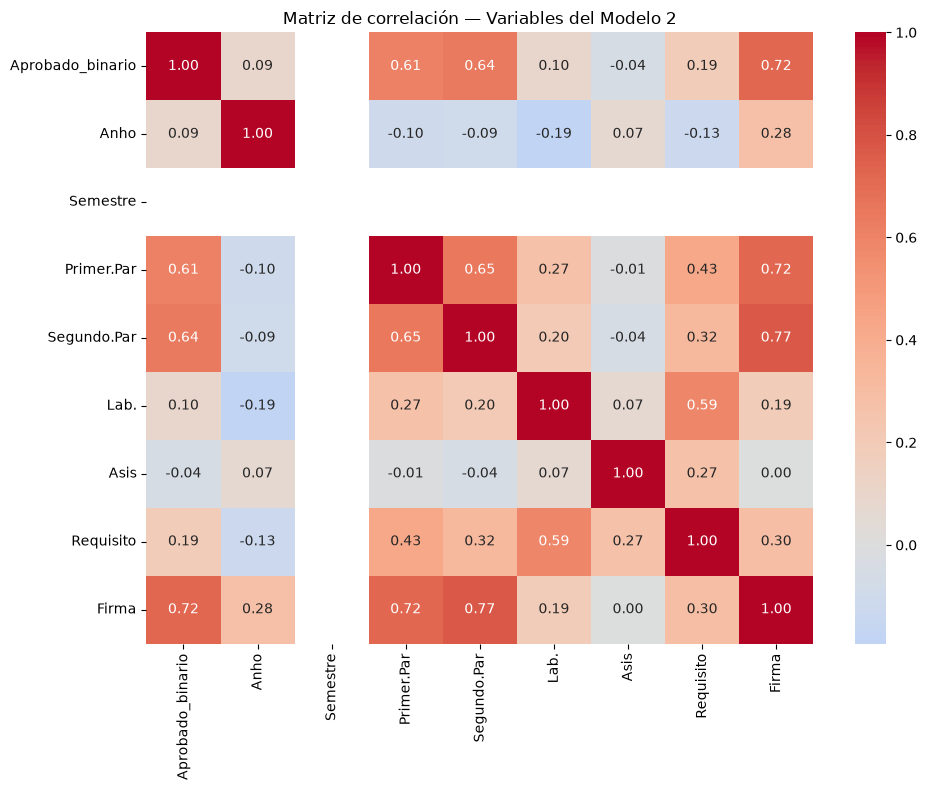

In [388]:
variables_corr = [
    "Aprobado_binario",
    "Anho",
    "Semestre",
    "Primer.Par",
    "Segundo.Par",
    "Lab.",
    "Asis",
    "Requisito",
    "Firma"
]

variables_corr = [
    c for c in variables_corr
    if c in df.columns
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[variables_corr].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación — Variables del Modelo 2")

plt.tight_layout()
plt.show()

## Comparación visual de los modelos

In [389]:
resultados_totales

,Experimento,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Modelo 1: Carrera + Año + Semestre,Regresión Logística,0.451,0.226,0.574,0.324,0.507,0.233
1,Modelo 1: Carrera + Año + Semestre,Decision Tree,0.451,0.226,0.574,0.324,0.507,0.233
2,Modelo 1: Carrera + Año + Semestre,Random Forest,0.451,0.226,0.574,0.324,0.507,0.233
3,Modelo 1: Carrera + Año + Semestre,Gradient Boosting,0.451,0.226,0.574,0.324,0.507,0.233
4,Modelo 2: Carrera + periodo + desempeño,Regresión Logística,0.898,0.713,0.934,0.809,0.955,0.866
5,Modelo 2: Carrera + periodo + desempeño,Decision Tree,0.883,0.683,0.918,0.783,0.949,0.852
6,Modelo 2: Carrera + periodo + desempeño,Random Forest,0.891,0.686,0.967,0.803,0.965,0.903
7,Modelo 2: Carrera + periodo + desempeño,Gradient Boosting,0.925,0.781,0.934,0.851,0.970,0.915


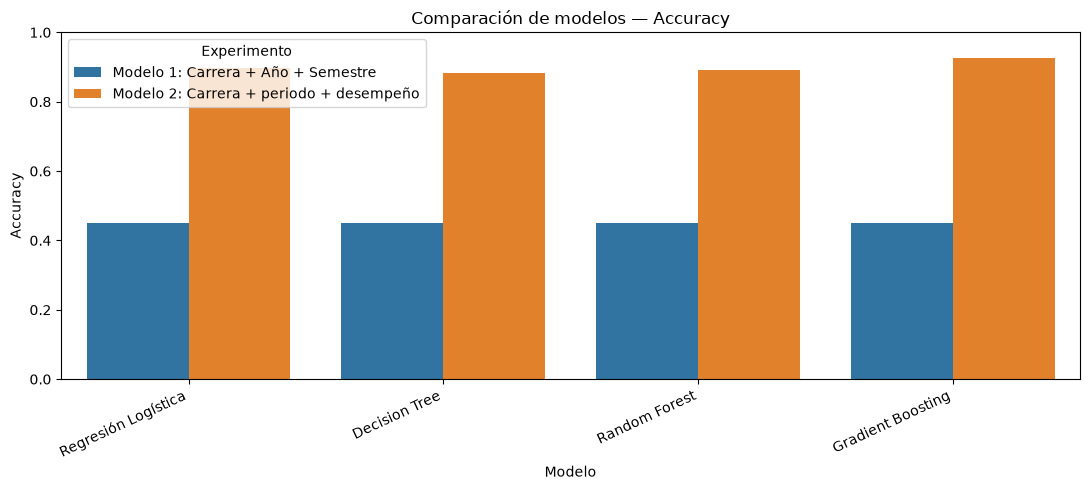

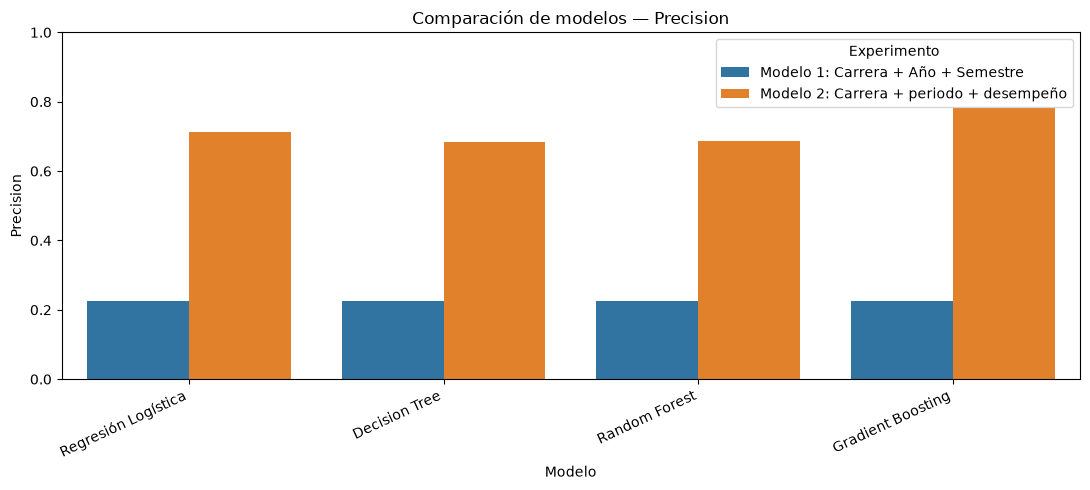

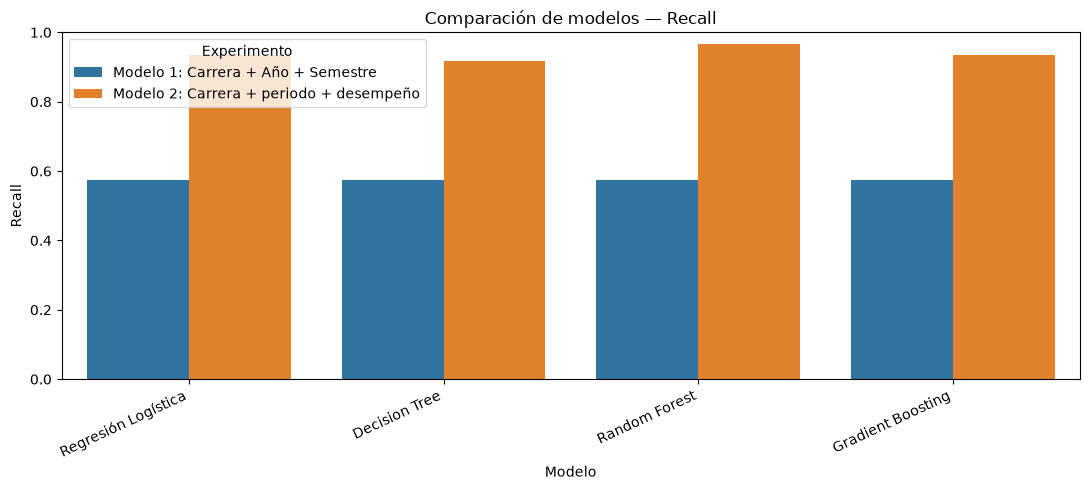

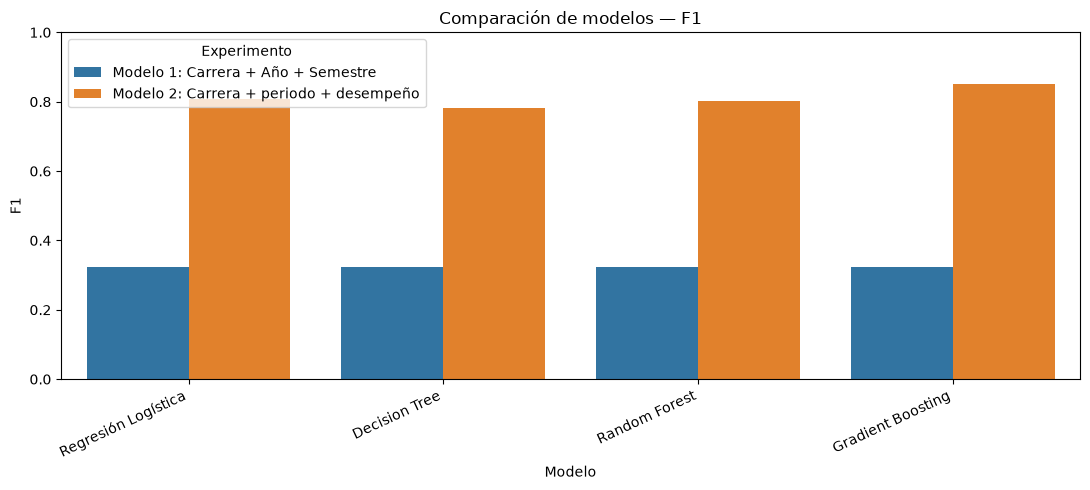

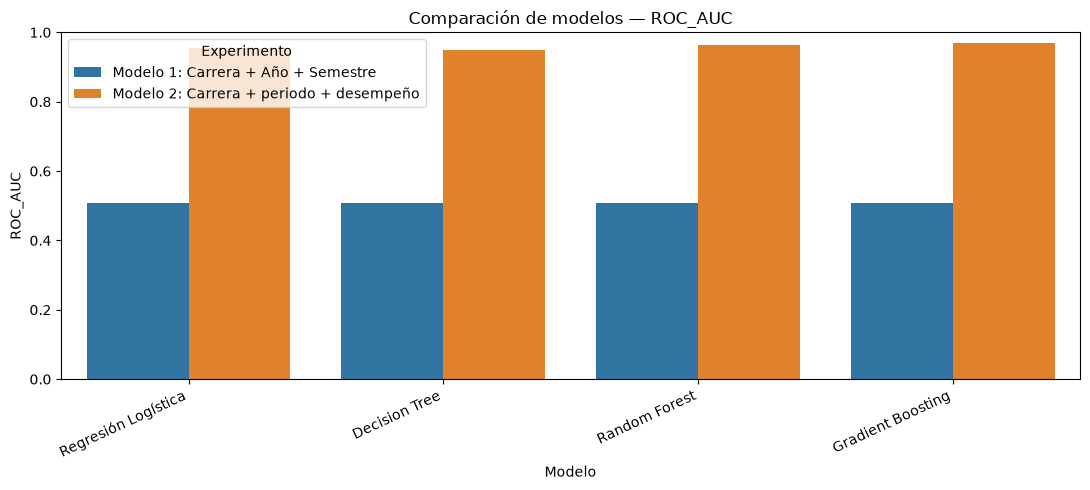

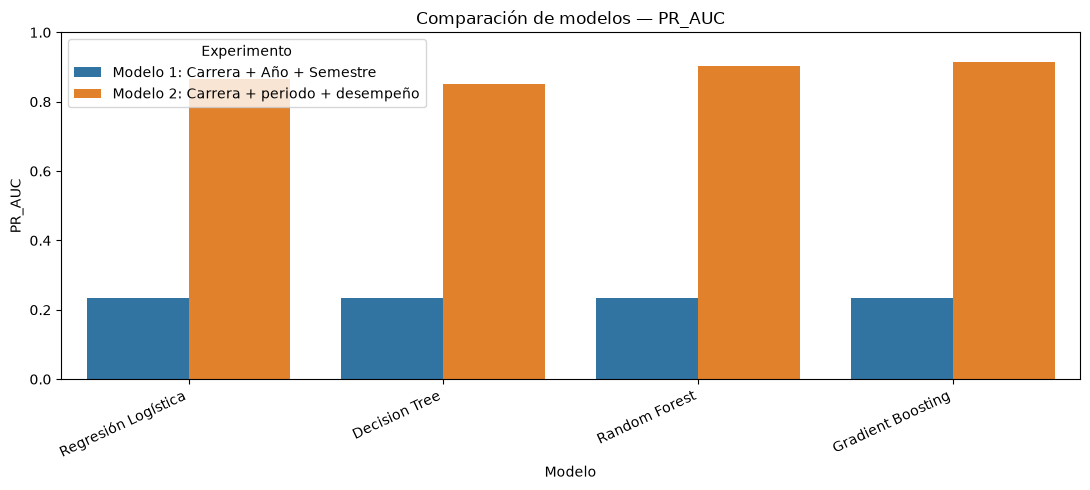

In [390]:
metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

for metrica in metricas:

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=resultados_totales,
        x="Modelo",
        y=metrica,
        hue="Experimento"
    )

    plt.ylim(0, 1)
    plt.ylabel(metrica)
    plt.xlabel("Modelo")
    plt.title(f"Comparación de modelos — {metrica}")

    plt.xticks(rotation=25, ha="right")

    plt.tight_layout()
    plt.show()